Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


In [71]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [72]:
# Notebook znajduje się w:
#
# ROOT_DIR:

ROOT_DIR = project_root()

FILTERED_DATA_DIR = project_path("data/processed")

EDA_DIR = project_path("results/eda")
FIGURES_DIR = EDA_DIR / "figures_filtered"
RESULTS_DIR = EDA_DIR / "results_filtered"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FILTERED_FULL_PATH = FILTERED_DATA_DIR / "users_items_filtered.csv"
TRAIN_VAL_PATH = FILTERED_DATA_DIR / "users_items_filtered_train_val.csv"
TEST_PATH = FILTERED_DATA_DIR / "users_items_filtered_test.csv"
COLD_START_PATH = FILTERED_DATA_DIR / "cold_start_users.csv"

print("ROOT_DIR:", ROOT_DIR)
print("FILTERED_FULL_PATH:", FILTERED_FULL_PATH, FILTERED_FULL_PATH.exists())
print("TRAIN_VAL_PATH:", TRAIN_VAL_PATH, TRAIN_VAL_PATH.exists())
print("TEST_PATH:", TEST_PATH, TEST_PATH.exists())
print("COLD_START_PATH:", COLD_START_PATH, COLD_START_PATH.exists())

ROOT_DIR: D:\Studiowe\Licencjat\modele
FILTERED_FULL_PATH: D:\Studiowe\Licencjat\modele\data_implicit_filtered\users_items_filtered.csv True
TRAIN_VAL_PATH: D:\Studiowe\Licencjat\modele\data_implicit_filtered\users_items_filtered_train_val.csv True
TEST_PATH: D:\Studiowe\Licencjat\modele\data_implicit_filtered\users_items_filtered_test.csv True
COLD_START_PATH: D:\Studiowe\Licencjat\modele\data_implicit_filtered\cold_start_users.csv True


In [73]:
train_val_df = pd.read_csv(TRAIN_VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

if FILTERED_FULL_PATH.exists():
    users_items_filtered = pd.read_csv(FILTERED_FULL_PATH)
    full_source = "users_items_filtered.csv"
else:
    users_items_filtered = pd.concat(
        [train_val_df, test_df],
        ignore_index=True
    )
    full_source = "concat(train_val_df, test_df)"

if COLD_START_PATH.exists():
    cold_start_users = pd.read_csv(COLD_START_PATH)
else:
    cold_start_users = None

print("Full filtered source:", full_source)
print("users_items_filtered:", users_items_filtered.shape)
print("train_val_df:", train_val_df.shape)
print("test_df:", test_df.shape)

if cold_start_users is not None:
    print("cold_start_users:", cold_start_users.shape)

C:\Users\misie\AppData\Local\Temp\ipykernel_20420\3315509632.py:1: DtypeWarning: Columns (0: user_id) have mixed types. Specify dtype option on import or set low_memory=False.
  train_val_df = pd.read_csv(TRAIN_VAL_PATH)


Full filtered source: users_items_filtered.csv
users_items_filtered: (5132610, 4)
train_val_df: (4591379, 4)
test_df: (541231, 4)
cold_start_users: (16902, 4)


In [74]:
users_items_filtered.head()

,user_id,item_id,item_name,playtime_forever
0,76561197970982479,10,Counter-Strike,6
1,76561197970982479,20,Team Fortress Classic,0
2,76561197970982479,30,Day of Defeat,7
3,76561197970982479,40,Deathmatch Classic,0
4,76561197970982479,50,Half-Life: Opposing Force,0


In [75]:
users_items_filtered.info()

<class 'pandas.DataFrame'>
RangeIndex: 5132610 entries, 0 to 5132609
Data columns (total 4 columns):
 #   Column            Dtype
---  ------            -----
 0   user_id           str  
 1   item_id           int64
 2   item_name         str  
 3   playtime_forever  int64
dtypes: int64(2), str(2)
memory usage: 156.6 MB


In [76]:
n_interactions = len(users_items_filtered)
n_users = users_items_filtered["user_id"].nunique()
n_items = users_items_filtered["item_id"].nunique()

density = n_interactions / (n_users * n_items)

basic_stats_filtered = pd.DataFrame({
    "metric": [
        "interactions",
        "users",
        "items",
        "matrix_density",
        "train_val_interactions",
        "test_interactions",
        "train_val_users",
        "test_users",
        "train_val_items",
        "test_items",
    ],
    "value": [
        n_interactions,
        n_users,
        n_items,
        density,
        len(train_val_df),
        len(test_df),
        train_val_df["user_id"].nunique(),
        test_df["user_id"].nunique(),
        train_val_df["item_id"].nunique(),
        test_df["item_id"].nunique(),
    ],
})

basic_stats_filtered

,metric,value
0,interactions,5.132610e+06
1,users,6.294400e+04
2,items,9.198000e+03
3,matrix_density,8.865241e-03
4,train_val_interactions,4.591379e+06
5,test_interactions,5.412310e+05
6,train_val_users,6.294800e+04
7,test_users,6.294400e+04
8,train_val_items,9.198000e+03
9,test_items,8.328000e+03


In [77]:
basic_stats_filtered.to_csv(
    RESULTS_DIR / "basic_stats_filtered.csv",
    index=False,
)

In [78]:
user_counts_filtered = (
    users_items_filtered
    .groupby("user_id")
    .size()
    .rename("n_interactions")
)

item_counts_filtered = (
    users_items_filtered
    .groupby("item_id")
    .size()
    .rename("n_interactions")
)

print("Minimum interactions per user:", user_counts_filtered.min())
print("Minimum interactions per item:", item_counts_filtered.min())

Minimum interactions per user: 5
Minimum interactions per item: 5


In [79]:
filter_sanity = pd.DataFrame({
    "entity": ["user", "item"],
    "min_interactions": [
        user_counts_filtered.min(),
        item_counts_filtered.min(),
    ],
    "n_below_5": [
        (user_counts_filtered < 5).sum(),
        (item_counts_filtered < 5).sum(),
    ],
})

filter_sanity

,entity,min_interactions,n_below_5
0,user,5,0
1,item,5,0


In [80]:
user_counts_filtered.describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

count    62944.000000
mean        81.542482
std        138.794816
min          5.000000
1%           5.000000
5%           7.000000
25%         21.000000
50%         48.000000
75%         97.000000
95%        251.000000
99%        518.570000
max       7337.000000
Name: n_interactions, dtype: float64

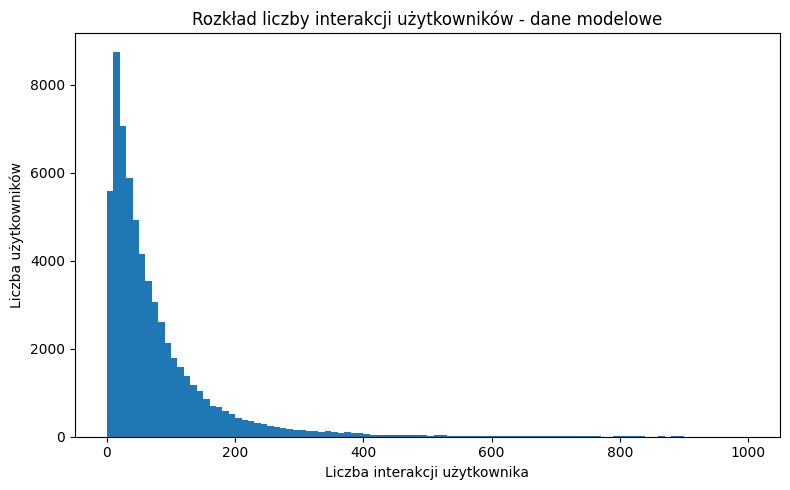

In [89]:
plt.figure(figsize=(8, 5))
plt.hist(user_counts_filtered, bins=100, range=(0, 1000))
plt.xlabel("Liczba interakcji użytkownika")
plt.ylabel("Liczba użytkowników")
plt.title("Rozkład liczby interakcji użytkowników - dane modelowe")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "filtered_user_interaction_counts_hist.png", dpi=300)
plt.show()

In [82]:
item_counts_filtered.describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

count     9198.000000
mean       558.013699
std       1945.931037
min          5.000000
1%           5.000000
5%           7.000000
25%         21.000000
50%         71.000000
75%        303.000000
95%       2515.050000
99%       8811.840000
max      45699.000000
Name: n_interactions, dtype: float64

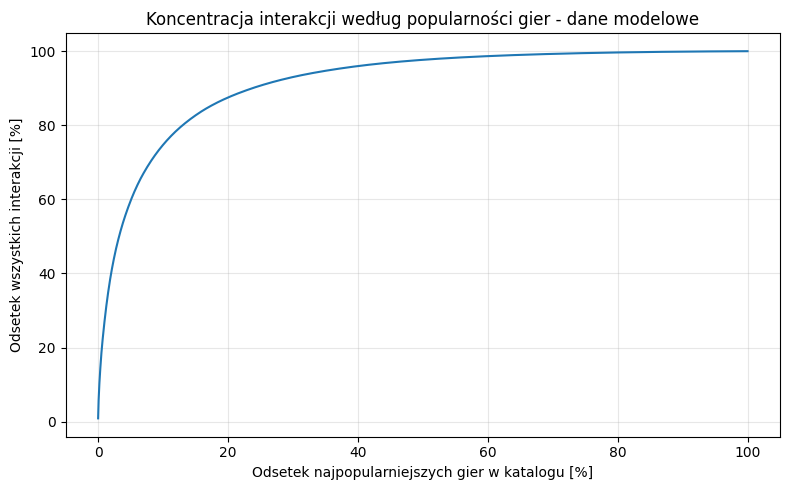

In [92]:
item_counts_filtered = (
    users_items_filtered
    .groupby("item_id")
    .size()
    .sort_values(ascending=False)
    .rename("n_interactions")
)

cumulative_interaction_share = (
    item_counts_filtered.cumsum() / item_counts_filtered.sum()
)

item_rank_share = (
    np.arange(1, len(item_counts_filtered) + 1) / len(item_counts_filtered)
)

plt.figure(figsize=(8, 5))

plt.plot(
    item_rank_share * 100,
    cumulative_interaction_share * 100
)

plt.xlabel("Odsetek najpopularniejszych gier w katalogu [%]")
plt.ylabel("Odsetek wszystkich interakcji [%]")
plt.title("Koncentracja interakcji według popularności gier - dane modelowe")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "filtered_item_popularity_concentration.png",
    dpi=300
)

plt.show()

In [84]:
top_shares = [0.01, 0.05, 0.10, 0.20]

popularity_concentration = []

for share in top_shares:
    n_top_items = max(1, int(np.ceil(share * len(item_counts_filtered))))
    interaction_share = item_counts_filtered.iloc[:n_top_items].sum() / item_counts_filtered.sum()
    
    popularity_concentration.append({
        "top_item_share": share,
        "n_top_items": n_top_items,
        "interaction_share": interaction_share,
    })

popularity_concentration = pd.DataFrame(popularity_concentration)
popularity_concentration

,top_item_share,n_top_items,interaction_share
0,0.01,92,0.271568
1,0.05,460,0.595493
2,0.10,920,0.747052
3,0.20,1840,0.874940


In [85]:
popularity_concentration.to_csv(
    RESULTS_DIR / "filtered_item_popularity_concentration.csv",
    index=False,
)

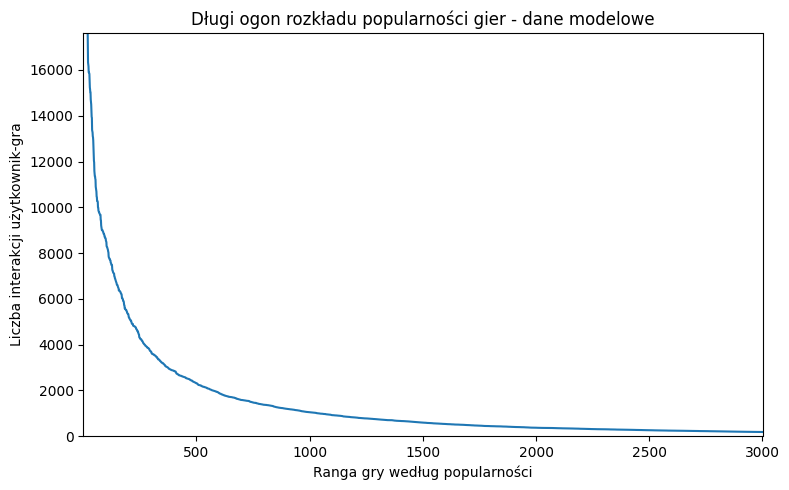

Zakres osi X: 1-3000
Limit osi Y ustawiony na 99. percentyl * 2: 17624
Największa liczba interakcji jednej gry: 45,699
Liczba gier w danych modelowych: 9,198


In [106]:
item_counts_filtered = (
    users_items_filtered
    .groupby("item_id")
    .size()
    .rename("n_interactions")
)

item_popularity_ranked = (
    item_counts_filtered
    .sort_values(ascending=False)
    .reset_index(drop=True)
)

x_limit = min(3000, len(item_popularity_ranked))
y_limit = item_popularity_ranked.quantile(0.99)

plt.figure(figsize=(8, 5))

plt.plot(
    np.arange(1, len(item_popularity_ranked) + 1),
    item_popularity_ranked.values,
    linewidth=1.5
)

plt.xlim(1, x_limit)
plt.ylim(0, y_limit * 2)

plt.xlabel("Ranga gry według popularności")
plt.ylabel("Liczba interakcji użytkownik-gra")
plt.title("Długi ogon rozkładu popularności gier - dane modelowe")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "filtered_item_popularity_long_tail_top3000_yclip_p99_times_2.png",
    dpi=300
)

plt.show()

print(f"Zakres osi X: 1-{x_limit}")
print(f"Limit osi Y ustawiony na 99. percentyl * 2: {y_limit * 2:.0f}")
print(f"Największa liczba interakcji jednej gry: {item_popularity_ranked.max():,}")
print(f"Liczba gier w danych modelowych: {len(item_popularity_ranked):,}")

,item_id,game_name,n_interactions
0,205790,Dota 2 Test,45699
1,730,Counter-Strike: Global Offensive,43023
2,4000,Garry's Mod,42485
3,304930,Unturned,37950
4,550,Left 4 Dead 2,36514
5,223530,Left 4 Dead 2 Beta,36514
6,105600,Terraria,28854
7,230410,Warframe,25610
8,620,Portal 2,24263
9,240,Counter-Strike: Source,24013


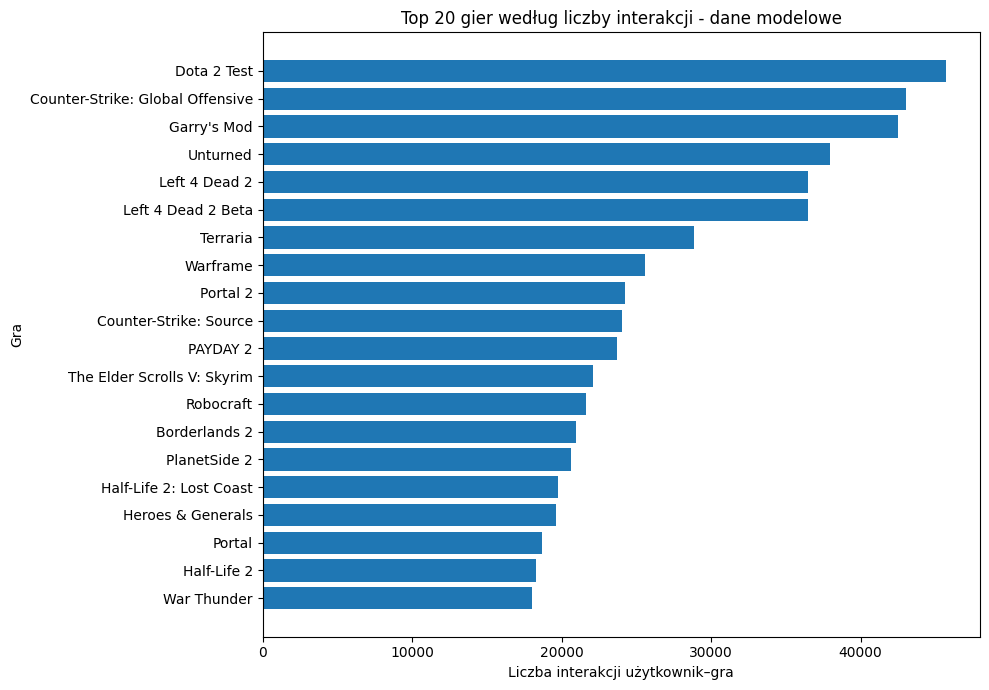

In [87]:
# Top N najpopularniejszych gier w danych modelowych
# z nazwami ze steam_games_final.csv oraz ręcznymi poprawkami dla brakujących ID

TOP_N = 20

STEAM_GAMES_PATH = project_path("data/raw") / "steam_games_final.csv"

steam_games = pd.read_csv(STEAM_GAMES_PATH)

# Kolumny w pliku steam_games_final.csv
GAME_ID_COL = "id"

possible_name_cols = ["title", "app_name", "name", "item_name"]

GAME_NAME_COL = None
for col in possible_name_cols:
    if col in steam_games.columns:
        GAME_NAME_COL = col
        break

if GAME_NAME_COL is None:
    raise ValueError(
        f"Nie znaleziono kolumny z nazwą gry. Dostępne kolumny: {steam_games.columns.tolist()}"
    )

# Ręczne uzupełnienie nazw dla popularnych itemów,
# których nie ma lub są błędnie opisane w steam_games_final.csv.
manual_game_names = {
    "205790": "Dota 2 Test",
    "223530": "Left 4 Dead 2 Beta",
    "218620": "PAYDAY 2",
    "72850": "The Elder Scrolls V: Skyrim",
    "236390": "War Thunder",
}

# Popularność gier w danych modelowych
top_items = (
    users_items_filtered
    .groupby("item_id")
    .size()
    .reset_index(name="n_interactions")
    .sort_values("n_interactions", ascending=False)
    .head(TOP_N)
)

# Ujednolicenie typów ID do merge'a
top_items["item_id"] = top_items["item_id"].astype(str)
steam_games[GAME_ID_COL] = steam_games[GAME_ID_COL].astype(str)

# Merge z metadanymi gier
top_items_named = top_items.merge(
    steam_games[[GAME_ID_COL, GAME_NAME_COL]],
    left_on="item_id",
    right_on=GAME_ID_COL,
    how="left"
)

# Nazwa z metadanych albo fallback unknown
top_items_named["game_name"] = top_items_named[GAME_NAME_COL].fillna(
    "unknown item_id=" + top_items_named["item_id"]
)

# Ręczne poprawki nazw
top_items_named["game_name"] = top_items_named["item_id"].map(
    manual_game_names
).fillna(top_items_named["game_name"])

top_items_named = top_items_named[
    ["item_id", "game_name", "n_interactions"]
]

display(top_items_named)

# Zapis tabeli
top_items_named.to_csv(
    RESULTS_DIR / f"filtered_top_{TOP_N}_games_by_interactions.csv",
    index=False
)

# Skracanie bardzo długich nazw na wykresie
def shorten_name(name, max_len=45):
    name = str(name)
    if len(name) <= max_len:
        return name
    return name[:max_len - 3] + "..."

plot_df = top_items_named.copy()
plot_df["game_name_short"] = plot_df["game_name"].apply(shorten_name)
plot_df = plot_df.sort_values("n_interactions", ascending=True)

# Wykres
plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["game_name_short"],
    plot_df["n_interactions"]
)

plt.xlabel("Liczba interakcji użytkownik–gra")
plt.ylabel("Gra")
plt.title(f"Top {TOP_N} gier według liczby interakcji - dane modelowe")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / f"filtered_top_{TOP_N}_games_by_interactions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [88]:
top_items_named.to_csv(
    RESULTS_DIR / f"filtered_top_{TOP_N}_games_by_interactions.csv",
    index=False
)